# 2026년 렉 코드 변화 이력 · 레이아웃 재작성용

2026년 출고에서 관측한 **존·복도·렉 코드**(층·선반 제외)의 등장·종료·재등장을 주 단위로 정리합니다.
사용자가 이 결과를 보고 기간별 렉 레이아웃을 다시 작성하기 위한 자료입니다.

- 원본: `outbound_2026-*.csv` 3개, `SHIPPED`, `pickingQuantity > 0`, 출고 요청 시각 기준.
- 주는 **월요일 시작**입니다. 첫 주(2025-12-29 주)는 1/1부터만 자료가 있습니다.
- **출고가 없으면 코드가 보이지 않습니다.** 종료는 렉 철거, 시작은 렉 신설을 뜻하지 않을 수 있습니다.
  재고가 없거나 출고가 적은 렉도 사라진 것처럼 보입니다. 행 수와 관측 주 수를 함께 봅니다.
- 같은 코드라도 시기마다 뜻이 다를 수 있습니다. 예를 들어 C 도입 전 A는 상온이었습니다.
  여기서는 코드 문자열만 비교하며 같은 물리 위치라고 가정하지 않습니다.
- 구간 경계는 **새로 등장·종료·재등장한 코드가 많은 주**를 자동으로 고른 제안입니다.
  사용자가 확인하고 조정합니다.

**출력:** `reports/mfc_rack_history_2026/`
- `rack_lifecycle.csv`: 코드별 첫·마지막 관측일, 행 수, 관측 주 수, 공백, 현재 레이아웃 포함 여부
- `change_events.csv`: 주별 신규·종료·재등장 코드
- `aisle_by_period.csv`: 구간 × 존·복도별 관측 렉 번호와 현재 레이아웃 대비 차이
- `timeline_<존>.png`: 존별 렉 코드 × 주 관측 타임라인

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap, LogNorm

from hit_stocks_analysis import find_project_root
from hit_stocks_analysis.mfc_layout import load_layout

ROOT = find_project_root()
OUTPUT = ROOT / "reports/mfc_rack_history_2026"
OUTPUT.mkdir(parents=True, exist_ok=True)
fonts = {font.name for font in font_manager.fontManager.ttflist}
for font in ("AppleGothic", "Malgun Gothic", "NanumGothic"):
    if font in fonts:
        plt.rcParams["font.family"] = font
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.facecolor"] = "#f8fafc"
pd.set_option("display.max_colwidth", 200)

layout = load_layout("2026-09")
# 현재 레이아웃의 렉: 지도에 놓인 관측 렉 + 위치 미확인 C08-00
CURRENT = set(layout.racks.index[layout.racks["observed"]]) | set(layout.unplaced["rack_code"])
REDS = LinearSegmentedColormap.from_list("rows", [
    "#fde4e3", "#f9bcb9", "#f28d8a", "#e34948", "#c42e2e", "#981b1e", "#6a1013"])

## 1. 일별 렉 코드 관측

In [2]:
SOURCES = str(ROOT / "outbound_2026-*.csv")
daily = duckdb.sql(f"""
    select regexp_extract(locationCode, '^([A-Z]\\d{{2}}-\\d{{2}})-\\d+$', 1) as rack_code,
           cast(cast(outboundRequestDateTime as timestamp) as date) as day,
           count(*) as n_rows
    from read_csv('{SOURCES}', all_varchar = true, quote = '"', escape = '"',
                  header = true)
    where status = 'SHIPPED' and cast(pickingQuantity as integer) > 0
    group by all
""").df()
assert daily["rack_code"].ne("").all(), "형식이 다른 로케이션 코드가 있습니다."
daily["day"] = pd.to_datetime(daily["day"])
daily["week"] = daily["day"] - pd.to_timedelta(daily["day"].dt.weekday, unit="D")
daily["zone"] = daily["rack_code"].str[0]
daily["aisle"] = daily["rack_code"].str[1:3]
daily["rack"] = daily["rack_code"].str[4:6]
WEEKS = pd.date_range(daily["week"].min(), daily["week"].max(), freq="7D")
LAST_DAY = daily["day"].max()
print(f"관측 {daily['day'].min():%Y-%m-%d} ~ {LAST_DAY:%Y-%m-%d} · 주 {len(WEEKS)}개 · "
      f"렉 코드 {daily['rack_code'].nunique()}개 · 행 {daily['n_rows'].sum():,}")
daily.groupby("zone").agg(codes=("rack_code", "nunique"), rows=("n_rows", "sum"),
                          first=("day", "min"), last=("day", "max"))

관측 2026-01-01 ~ 2026-09-27 · 주 39개 · 렉 코드 752개 · 행 2,376,631


,codes,rows,first,last
zone,,,,
A,235,666337,2026-01-01,2026-09-27
B,102,271041,2026-01-07,2026-09-27
C,107,225717,2026-07-04,2026-09-27
D,106,141787,2026-05-27,2026-09-27
I,43,88970,2026-01-01,2026-08-06
M,1,10639,2026-01-01,2026-09-27
S,1,5930,2026-01-01,2026-09-27
W,64,224801,2026-01-01,2026-08-09
X,86,719985,2026-01-01,2026-07-25


## 2. 코드별 수명과 주별 변화 이벤트

- **신규:** 2026년 자료에서 처음 관측된 주. 자료 첫 주는 제외합니다.
- **종료:** 마지막으로 관측된 주. 자료 마지막 2주 안의 마지막 관측은 종료로 보지 않습니다.
- **재등장:** `GAP_WEEKS`주 이상 관측되지 않다가 다시 관측된 주.
- 행 수가 `LOW_ROWS` 미만인 코드는 `소량` 표시를 붙입니다(오기록·일시 사용 가능성).

In [3]:
GAP_WEEKS = 3
LOW_ROWS = 10
weekly = daily.groupby(["rack_code", "week"])["n_rows"].sum().unstack("week")
weekly = weekly.reindex(columns=WEEKS).fillna(0).astype(int)

events, gap_info = [], {}
for rack_code, row in weekly.iterrows():
    seen = np.flatnonzero(row.to_numpy() > 0)
    first, last = seen[0], seen[-1]
    if first > 0:
        events.append((WEEKS[first], rack_code, "신규"))
    if last < len(WEEKS) - 2:
        events.append((WEEKS[last], rack_code, "종료"))
    gaps = [(a, b) for a, b in zip(seen, seen[1:]) if b - a - 1 >= GAP_WEEKS]
    for a, b in gaps:
        events.append((WEEKS[b], rack_code, "재등장"))
    gap_info[rack_code] = "; ".join(
        f"{WEEKS[a + 1]:%m-%d}~{WEEKS[b] - pd.Timedelta(days=1):%m-%d}" for a, b in gaps)

life = daily.groupby("rack_code").agg(
    zone=("zone", "first"), aisle=("aisle", "first"), rack=("rack", "first"),
    first_day=("day", "min"), last_day=("day", "max"), rows=("n_rows", "sum"),
    active_days=("day", "nunique"))
life["active_weeks"] = (weekly > 0).sum(axis=1)
life["gaps_3w_plus"] = pd.Series(gap_info)
life["in_current_layout"] = life.index.isin(CURRENT)
life["low_volume"] = life["rows"] < LOW_ROWS
life.to_csv(OUTPUT / "rack_lifecycle.csv", encoding="utf-8-sig")

events = pd.DataFrame(events, columns=["week", "rack_code", "event"]).join(
    life[["zone", "rows", "in_current_layout", "low_volume"]], on="rack_code")
events = events.sort_values(["week", "zone", "event", "rack_code"]).reset_index(drop=True)
events.to_csv(OUTPUT / "change_events.csv", index=False, encoding="utf-8-sig")
event_table = events.pivot_table(index="week", columns=["event", "zone"], values="rack_code",
                                 aggfunc="count", fill_value=0)
event_table

event       신규                    재등장              종료                        
zone         A   B    C   D  W  X   A  B  C  D  I   A  B  C  D   I   W   X  Z
week                                                                         
2026-01-05   1   1    0   0  0  0   0  0  0  0  0   0  0  0  0   1   0   0  0
2026-01-26   0   0    0   0  0  1   0  0  0  0  0   0  0  0  0   0   0   0  0
2026-02-16   2   0    0   0  0  0   1  0  0  0  0   0  0  0  0   0   0   0  0
2026-02-23   1   0    0   0  0  0   1  0  0  0  0   1  0  0  0   0   0   0  0
2026-03-02   0   0    0   0  1  0   1  0  0  0  0   0  0  0  0   0   0   0  0
2026-03-16   0   0    0   0  0  0   2  0  0  0  1   0  0  0  0   0   0   0  0
2026-03-30   0   0    0   0  0  1   0  0  0  0  0   0  0  0  0   0   0   0  0
2026-04-06   0   0    0   0  0  0   2  0  0  0  0   0  0  0  0   0   0   0  0
2026-04-13   0   0    0   0  0  0   0  0  0  0  0   1  0  0  0   0   0   0  0
2026-04-20   0   0    0   0  0  0   3  0  0  0  0   3  0  0  0   0   1   0  0
2026-04-27   1   0    0   0  0  0   1  0  0  0  0   1  0  0  0   1   0   0  0
2026-05-11   0   0    0   0  0  0   2  0  0  0  1   0  0  0  0   0   0   0  0
2026-05-18   0   0    0   0  0  1   0  0  0  0  0   4  0  0  0   0   0   1  0
2026-05-25   0   0    0  95  0  0   0  0  0  0  0  73  0  0  1   0   0   0  0
2026-06-01   0   0    0   0  0  0   1  0  0  0  1   1  0  0  0   0   0   0  4
2026-06-08   2   0    0   0  0  0   0  0  0  0  0   0  0  0  0   0   0   0  0
2026-06-22   0   0    0   0  2  0   0  0  0  0  0   1  0  0  0   0   0   0  0
2026-06-29   0   0  100   8  0  1   0  0  0  1  0  47  0  0  0   0   0   1  0
2026-07-06   0   0    7   1  0  0   1  0  0  0  1   2  0  2  0   0   0   0  3
2026-07-13   0  52    0   0  0  0   0  0  0  0  0   0  0  0  0   1   0  61  0
2026-07-20   0  32    0   1  0  0   1  1  0  0  1   0  0  0  0   8   4  23  0
2026-07-27   3   0    0   0  0  0  60  0  0  0  0   1  0  0  0  29  26   0  0
2026-08-03  18   0    0   0  0  0  12  0  0  0  0   0  1  0  0   3  33   0  0
2026-08-10   0   0    0   0  0  0   0  0  1  0  0   0  0  1  2   0   0   0  0
2026-08-17   0  14    0   0  0  0   1  0  0  0  0   1  0  0  0   0   0   0  0
2026-08-24   0   3    0   1  0  0   0  0  0  0  0   1  1  0  3   0   0   0  0
2026-08-31   1   0    0   0  0  0   3  0  0  0  0   0  0  2  0   0   0   0  0
2026-09-07   0   0    0   0  0  0   0  0  0  0  0   0  0  1  1   0   0   0  0
2026-09-21   0   0    0   0  0  0   1  0  0  0  0   0  0  0  0   0   0   0  0

## 3. 구간 경계 제안

신규·종료·재등장 코드가 `BOUNDARY_MIN`개 이상인 주를 구간 시작으로 봅니다(소량 코드 제외).
경계는 `BOUNDARIES`를 직접 고쳐 조정할 수 있습니다.

In [4]:
BOUNDARY_MIN = 10
counts = events.loc[~events["low_volume"]].groupby("week").size()
BOUNDARIES = [WEEKS[0], *counts.index[counts >= BOUNDARY_MIN]]
period_starts = pd.DatetimeIndex(sorted(set(BOUNDARIES)))
period_ends = [*(period_starts[1:] - pd.Timedelta(days=1)), LAST_DAY]
PERIODS = [(max(s, daily["day"].min()), e) for s, e in zip(period_starts, period_ends)]
for i, (s, e) in enumerate(PERIODS, 1):
    week_events = events.loc[events["week"].eq(s) & ~events["low_volume"]]
    note = week_events.groupby(["event", "zone"]).size()
    note = ", ".join(f"{z} {ev} {n}" for (ev, z), n in note.items()) or "자료 시작"
    print(f"P{i}: {s:%Y-%m-%d} ~ {e:%Y-%m-%d} · 시작 주 이벤트: {note}")

P1: 2026-01-01 ~ 2026-05-24 · 시작 주 이벤트: 자료 시작
P2: 2026-05-25 ~ 2026-06-28 · 시작 주 이벤트: D 신규 94, A 종료 73
P3: 2026-06-29 ~ 2026-07-05 · 시작 주 이벤트: C 신규 100, D 신규 8, X 신규 1, D 재등장 1, A 종료 47, X 종료 1
P4: 2026-07-06 ~ 2026-07-12 · 시작 주 이벤트: C 신규 7, D 신규 1, A 재등장 1, I 재등장 1, A 종료 2, C 종료 2, Z 종료 3
P5: 2026-07-13 ~ 2026-07-19 · 시작 주 이벤트: B 신규 52, I 종료 1, X 종료 61
P6: 2026-07-20 ~ 2026-07-26 · 시작 주 이벤트: B 신규 32, D 신규 1, B 재등장 1, I 재등장 1, I 종료 8, W 종료 4, X 종료 23
P7: 2026-07-27 ~ 2026-08-02 · 시작 주 이벤트: A 신규 3, A 재등장 60, A 종료 1, I 종료 29, W 종료 26
P8: 2026-08-03 ~ 2026-08-16 · 시작 주 이벤트: A 신규 18, A 재등장 12, B 종료 1, I 종료 3, W 종료 33
P9: 2026-08-17 ~ 2026-09-27 · 시작 주 이벤트: B 신규 14, A 재등장 1, A 종료 1


## 4. 구간 × 존·복도별 렉 번호와 현재 레이아웃 비교

각 구간에서 관측된 렉 번호를 복도별로 압축해 보여줍니다. 예를 들어 `01-07,09`는 01~07과 09입니다.
`현재에 없음`은 그 구간에 관측됐지만 현재 레이아웃에 없는 번호입니다.
`구간에 없음`은 현재 레이아웃에는 있지만 그 구간 출고에서 관측되지 않은 번호입니다.
현재 레이아웃에 없는 존(X·I·W 등)은 전체가 `현재에 없음`입니다.

In [5]:
def compact(numbers):
    numbers = sorted(int(n) for n in numbers)
    parts, start = [], None
    for i, n in enumerate(numbers):
        start = n if start is None else start
        if i + 1 == len(numbers) or numbers[i + 1] != n + 1:
            parts.append(f"{start:02}" if start == n else f"{start:02}-{n:02}")
            start = None
    return ",".join(parts)


current = pd.Series(sorted(CURRENT))
current = pd.DataFrame({"zone": current.str[0], "aisle": current.str[1:3],
                        "rack": current.str[4:6]})
rows = []
for i, (s, e) in enumerate(PERIODS, 1):
    part = daily.loc[daily["day"].between(s, e)]
    seen = part.groupby(["zone", "aisle"]).agg(racks=("rack", set), rows=("n_rows", "sum"))
    cur = current.groupby(["zone", "aisle"])["rack"].agg(set)
    for (zone, aisle) in sorted(set(seen.index) | set(cur.index)):
        observed = seen["racks"].get((zone, aisle), set())
        now = cur.get((zone, aisle), set())
        rows.append({
            "period": f"P{i}", "start": f"{s:%Y-%m-%d}", "end": f"{e:%Y-%m-%d}",
            "zone": zone, "aisle": aisle, "rows": int(seen["rows"].get((zone, aisle), 0)),
            "racks_seen": compact(observed), "n_seen": len(observed),
            "현재에 없음": compact(observed - now), "구간에 없음": compact(now - observed),
            "same_as_current": observed == now,
        })
aisle_by_period = pd.DataFrame(rows)
aisle_by_period.to_csv(OUTPUT / "aisle_by_period.csv", index=False, encoding="utf-8-sig")

# 구간별 요약: 존마다 현재 레이아웃과 같은 복도 수 / 관측 복도 수
summary = (aisle_by_period.loc[aisle_by_period["n_seen"] > 0]
           .groupby(["period", "start", "end", "zone"])
           .agg(aisles=("aisle", "size"), same=("same_as_current", "sum"), rows=("rows", "sum"))
           .assign(text=lambda d: d["same"].astype(str) + "/" + d["aisles"].astype(str)))
summary["text"].unstack("zone").fillna("–")

,,zone,A,B,C,D,I,M,S,W,X,Z
period,start,end,,,,,,,,,,
P1,2026-01-01,2026-05-24,0/10,0/1,–,–,0/8,0/1,0/1,0/12,0/9,0/7
P2,2026-05-25,2026-06-28,0/10,0/1,–,4/8,0/8,0/1,0/1,0/11,0/9,0/7
P3,2026-06-29,2026-07-05,0/10,–,4/9,6/9,0/8,0/1,0/1,0/11,0/9,0/3
P4,2026-07-06,2026-07-12,0/2,–,6/9,6/9,0/8,0/1,0/1,0/11,0/9,0/3
P5,2026-07-13,2026-07-19,–,2/7,8/9,7/9,0/8,0/1,0/1,0/11,0/9,–
P6,2026-07-20,2026-07-26,0/2,2/9,9/9,6/9,0/8,0/1,0/1,0/11,0/4,–
P7,2026-07-27,2026-08-02,4/8,2/9,9/9,6/9,0/6,0/1,0/1,0/11,–,–
P8,2026-08-03,2026-08-16,9/12,2/9,8/9,6/9,0/2,0/1,0/1,0/8,–,–
P9,2026-08-17,2026-09-27,11/13,9/10,9/9,8/9,–,0/1,0/1,–,–,–


표의 `a/b`는 그 구간에 관측된 복도 b개 중 렉 번호 집합이 현재 레이아웃과 같은 복도가 a개라는 뜻입니다.
출고가 없던 렉 때문에 같지 않게 나올 수 있으므로 `aisle_by_period.csv`에서 번호를 직접 확인합니다.

## 5. 존별 관측 타임라인

행 = 렉 코드, 열 = 주, 색 = 그 주 피킹 행 수(로그 척도). 흰 칸은 관측 없음입니다.
세로선은 3절의 구간 경계입니다. 현재 레이아웃에 없는 코드는 이름 앞에 `*`를 붙였습니다.

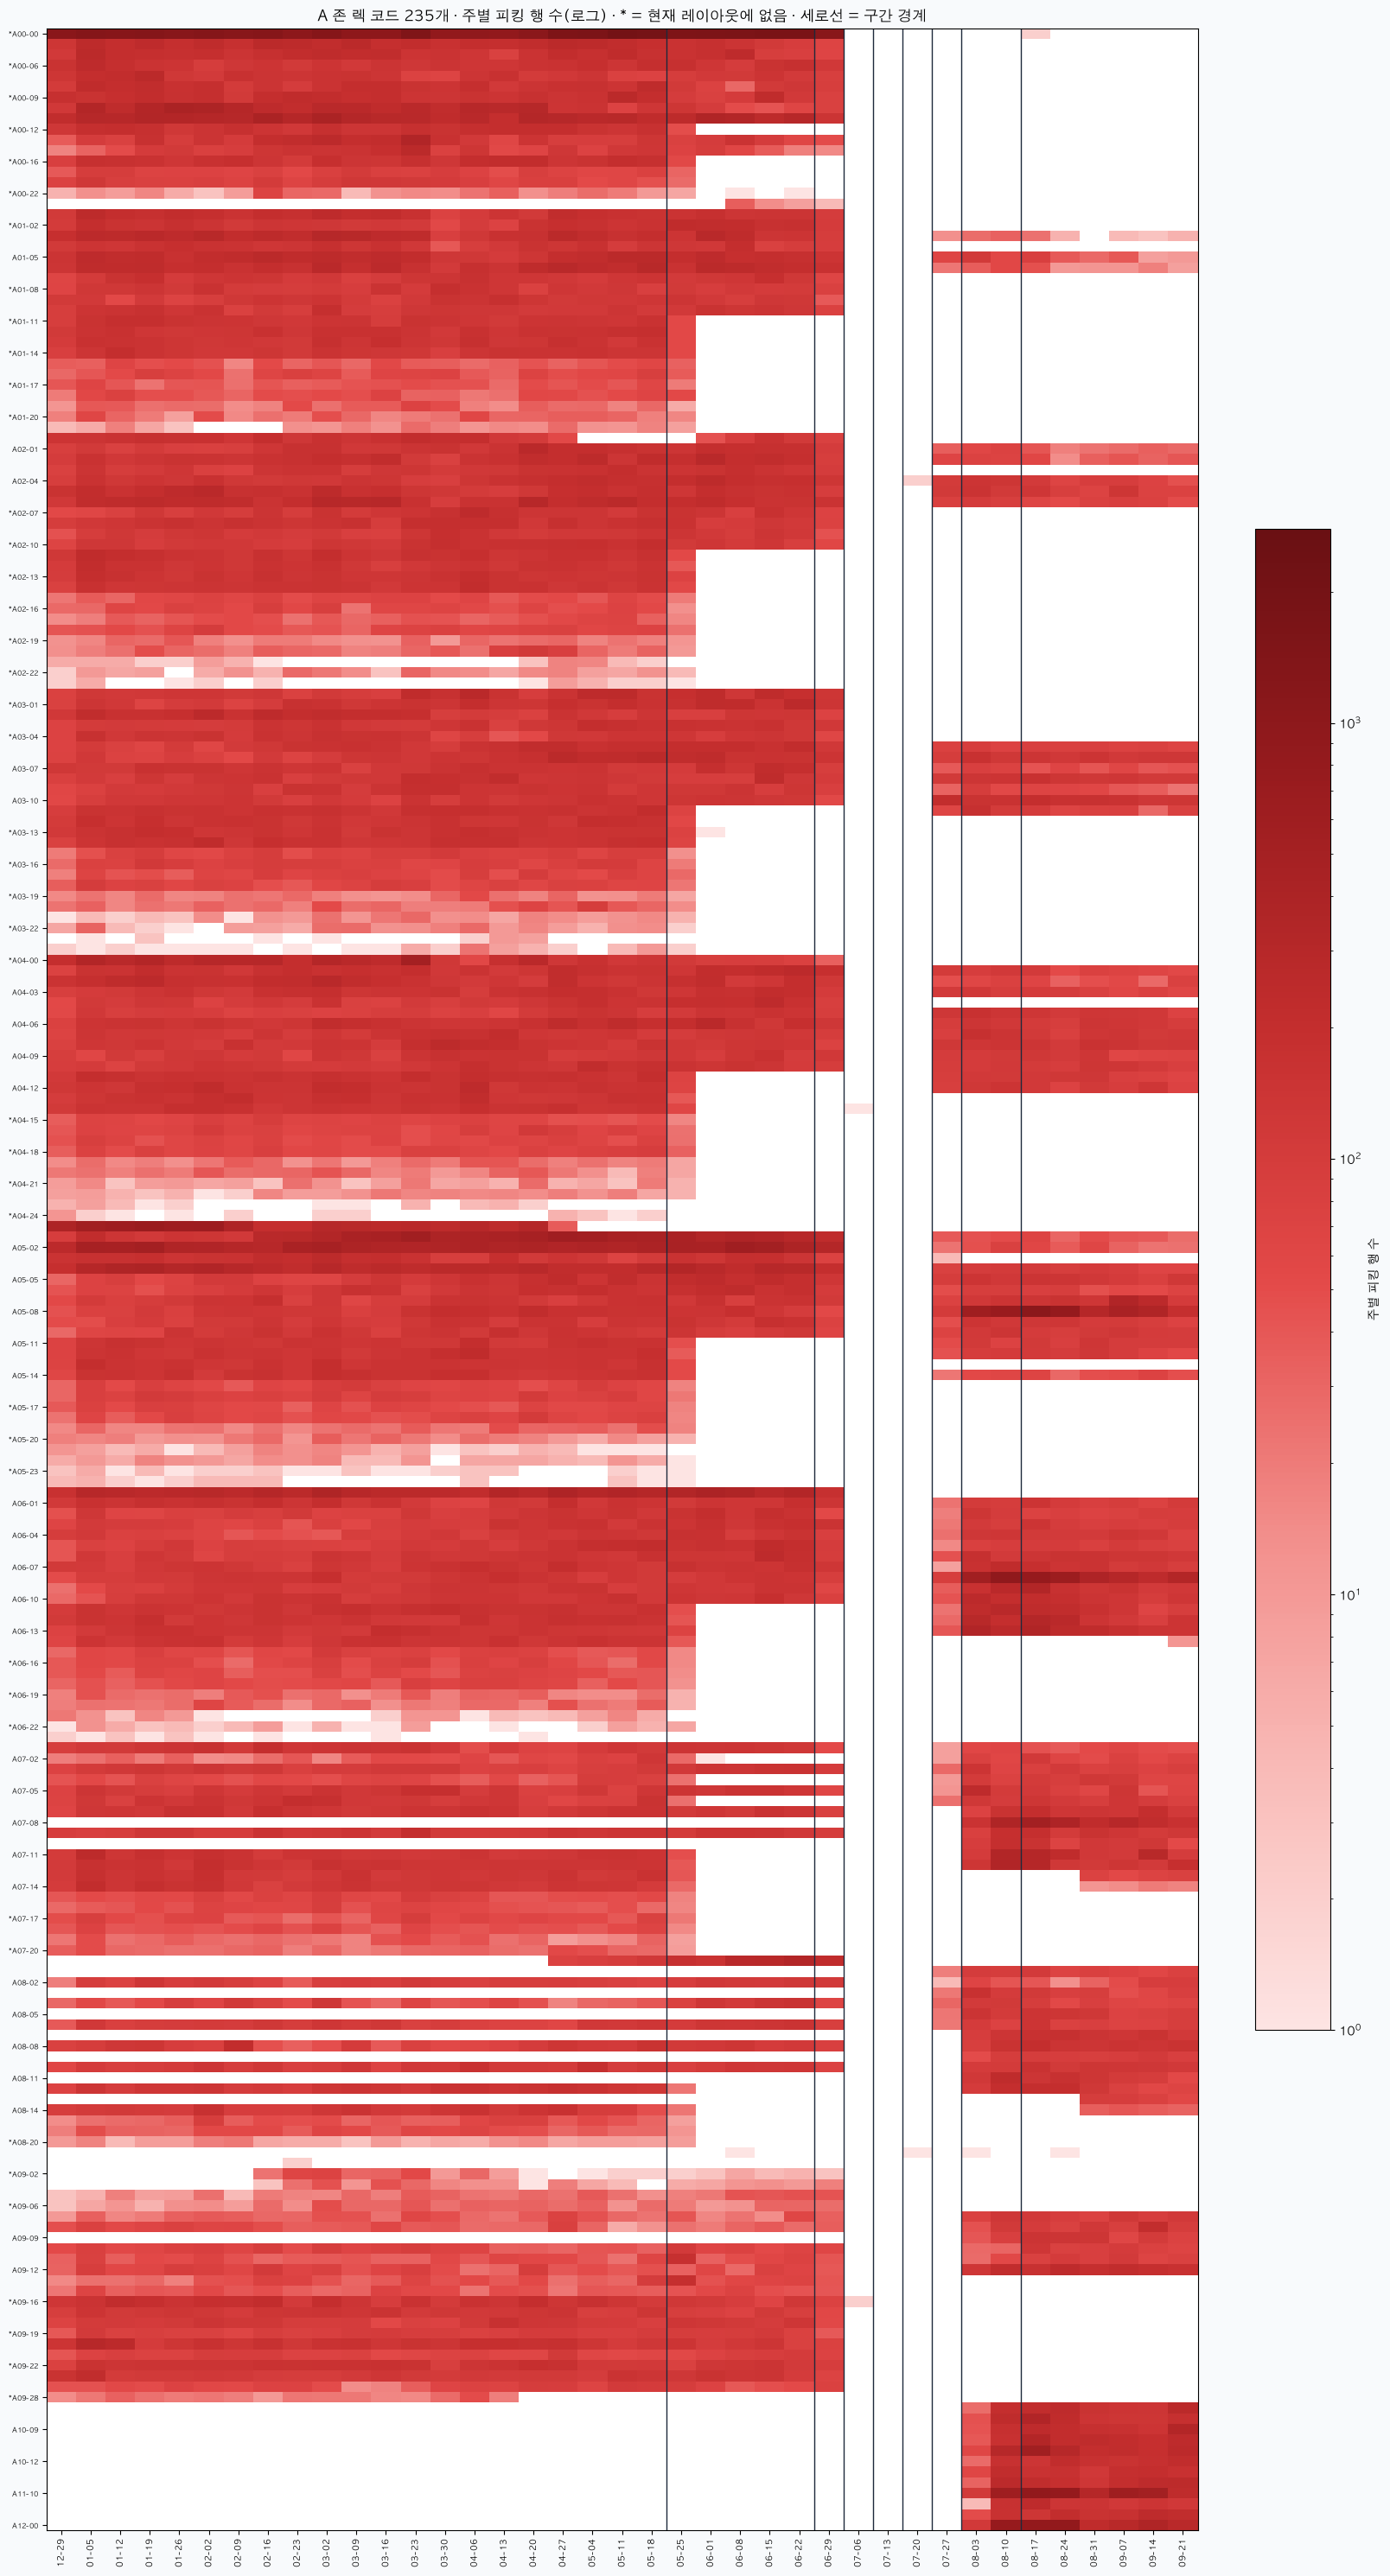

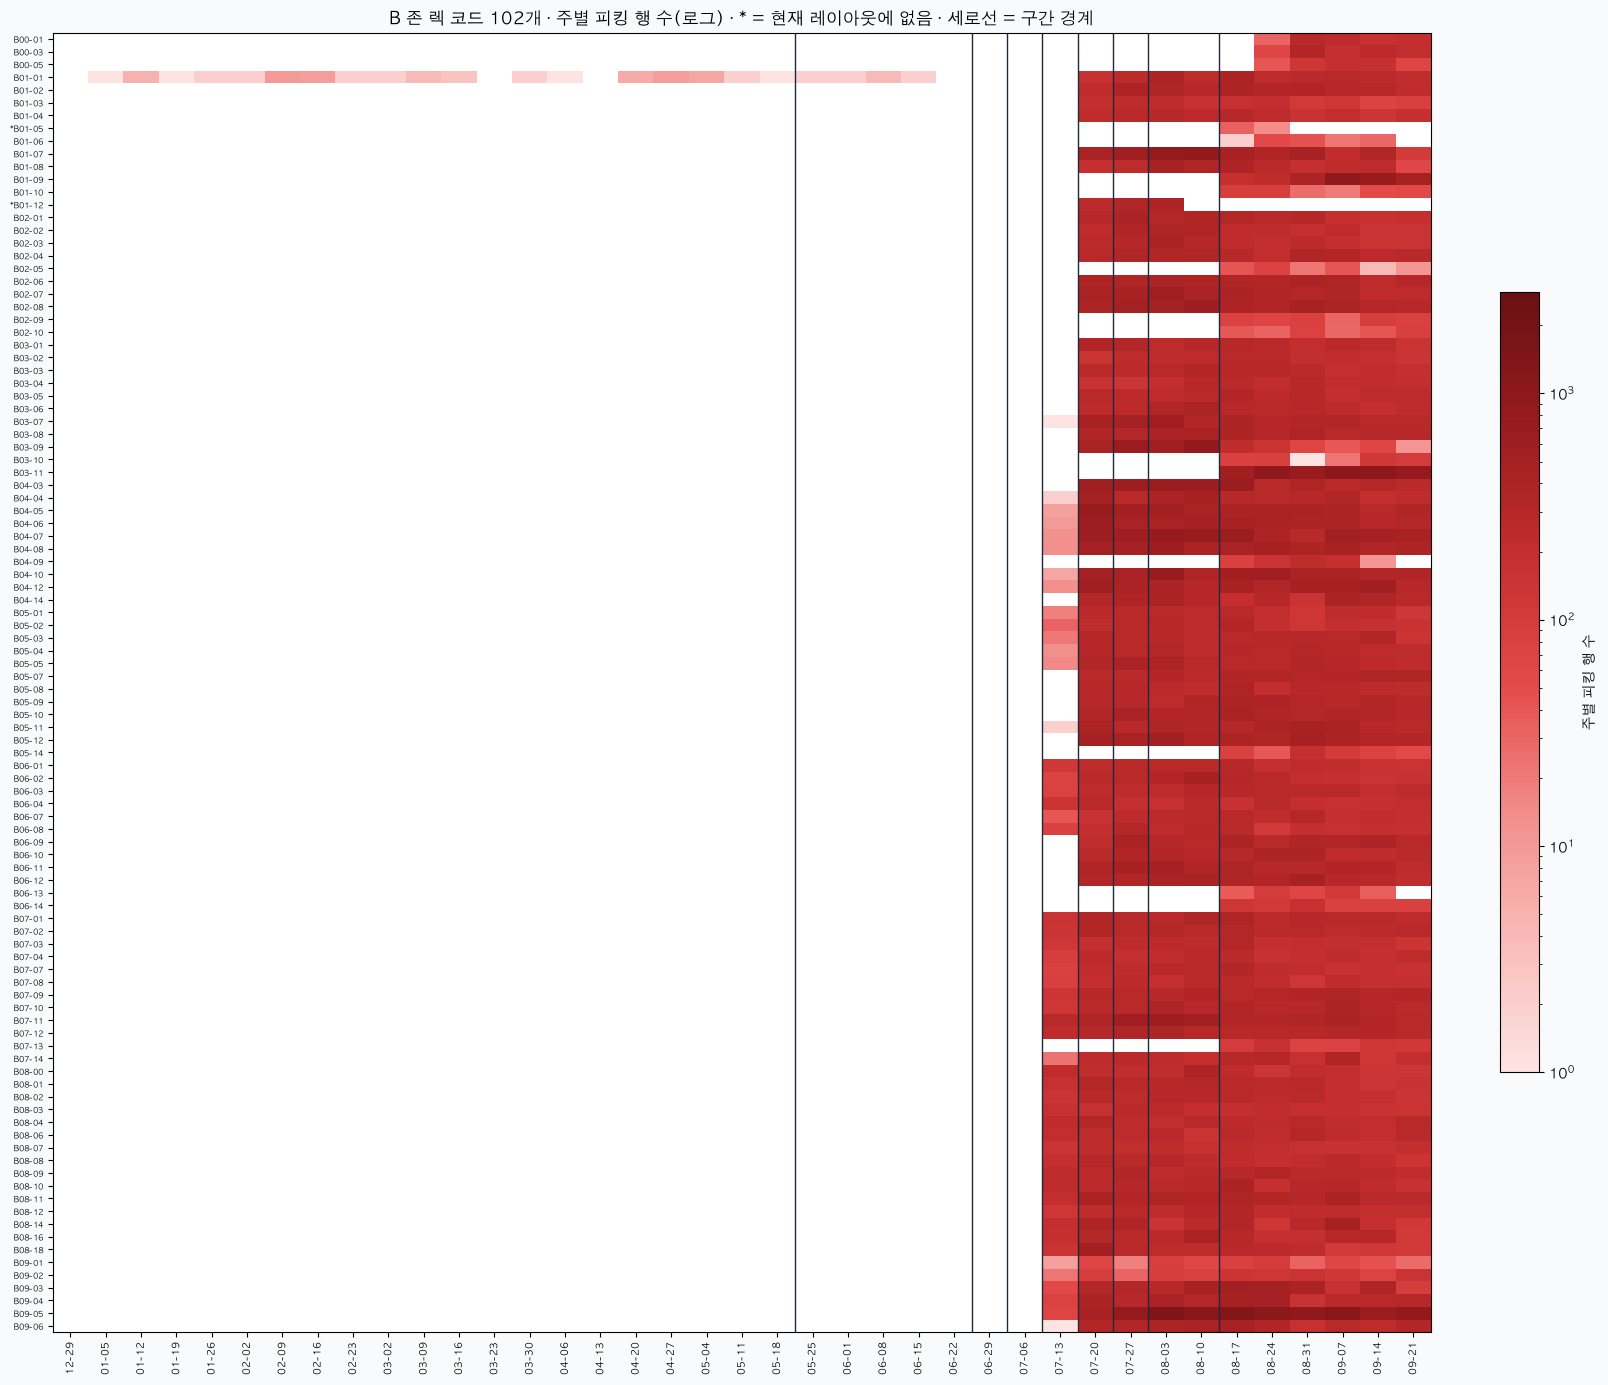

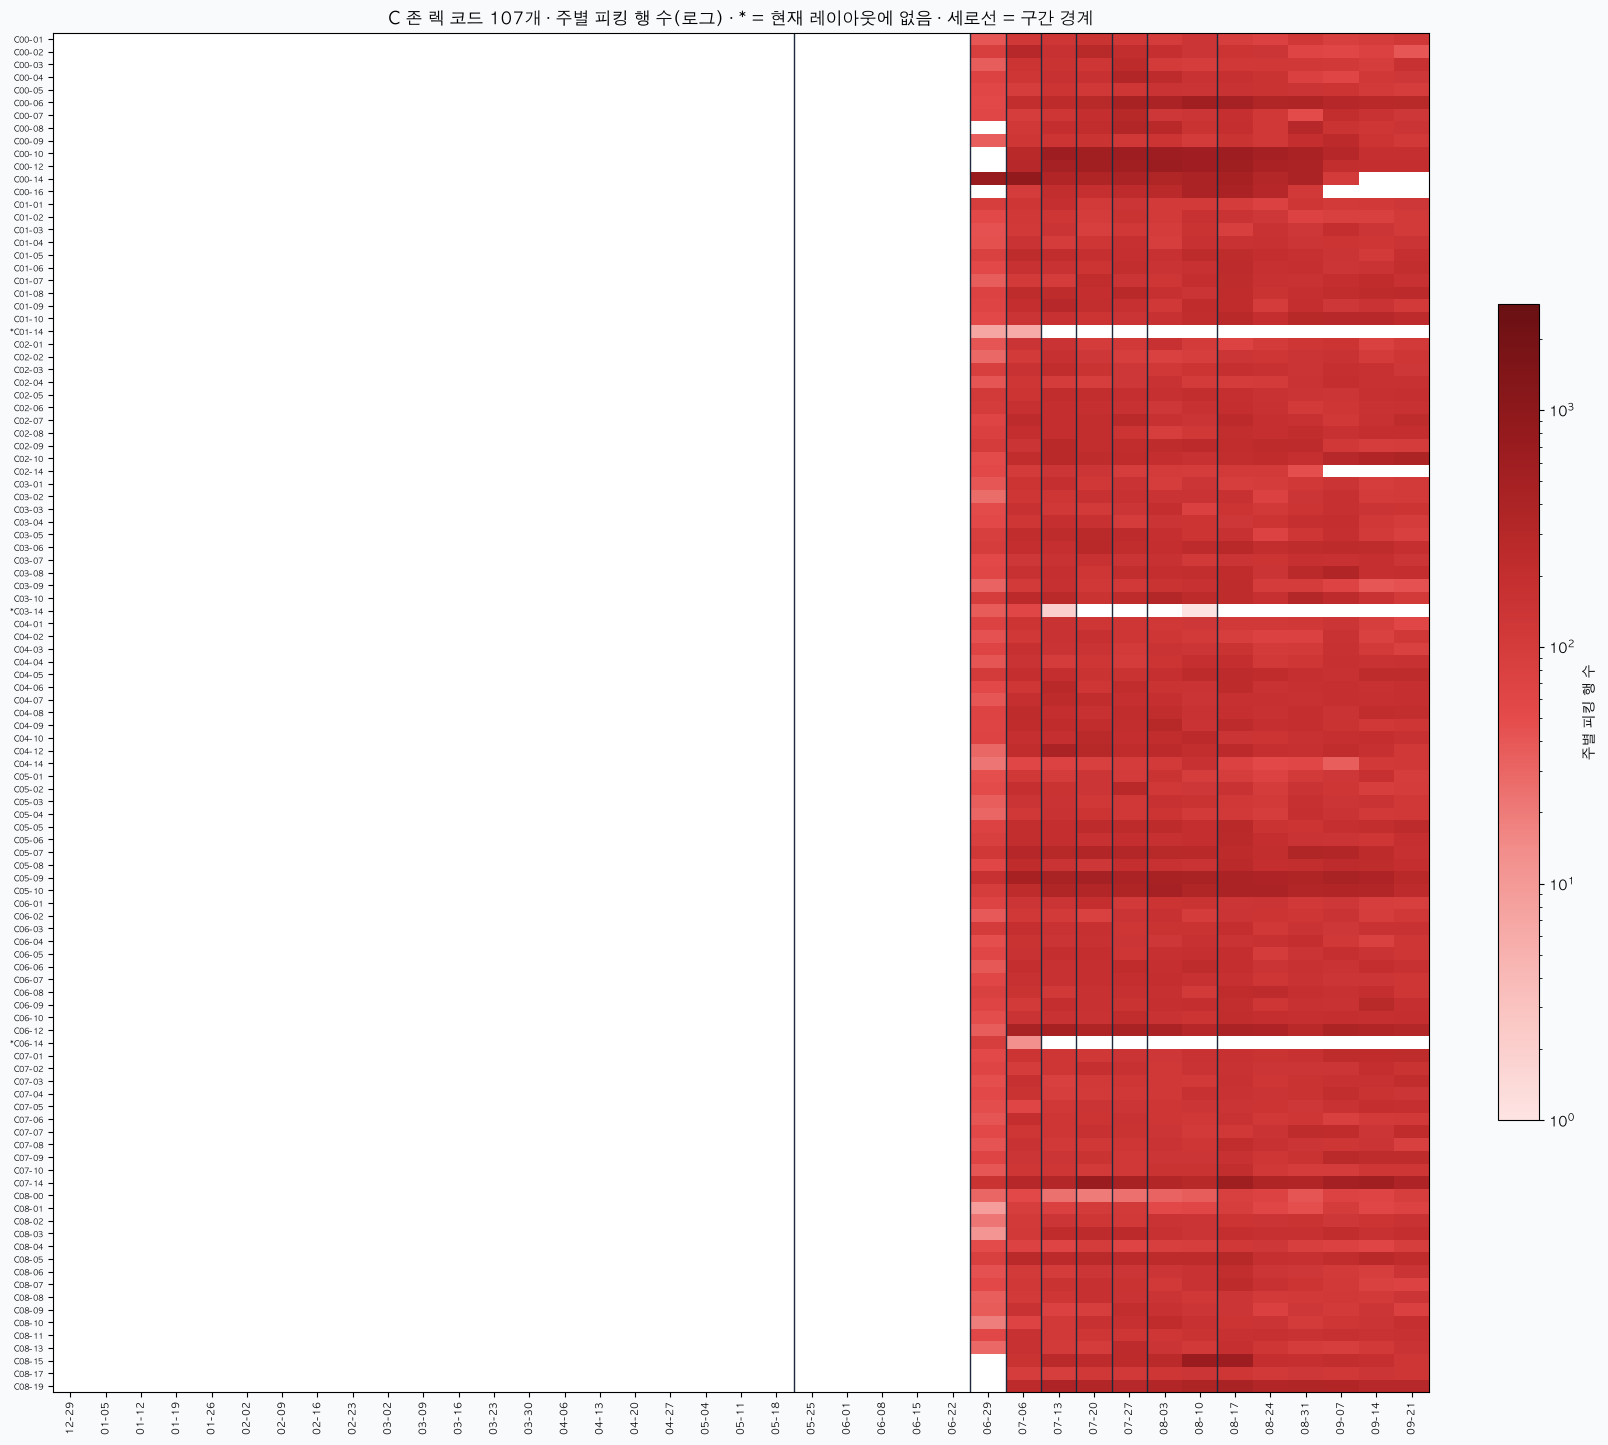

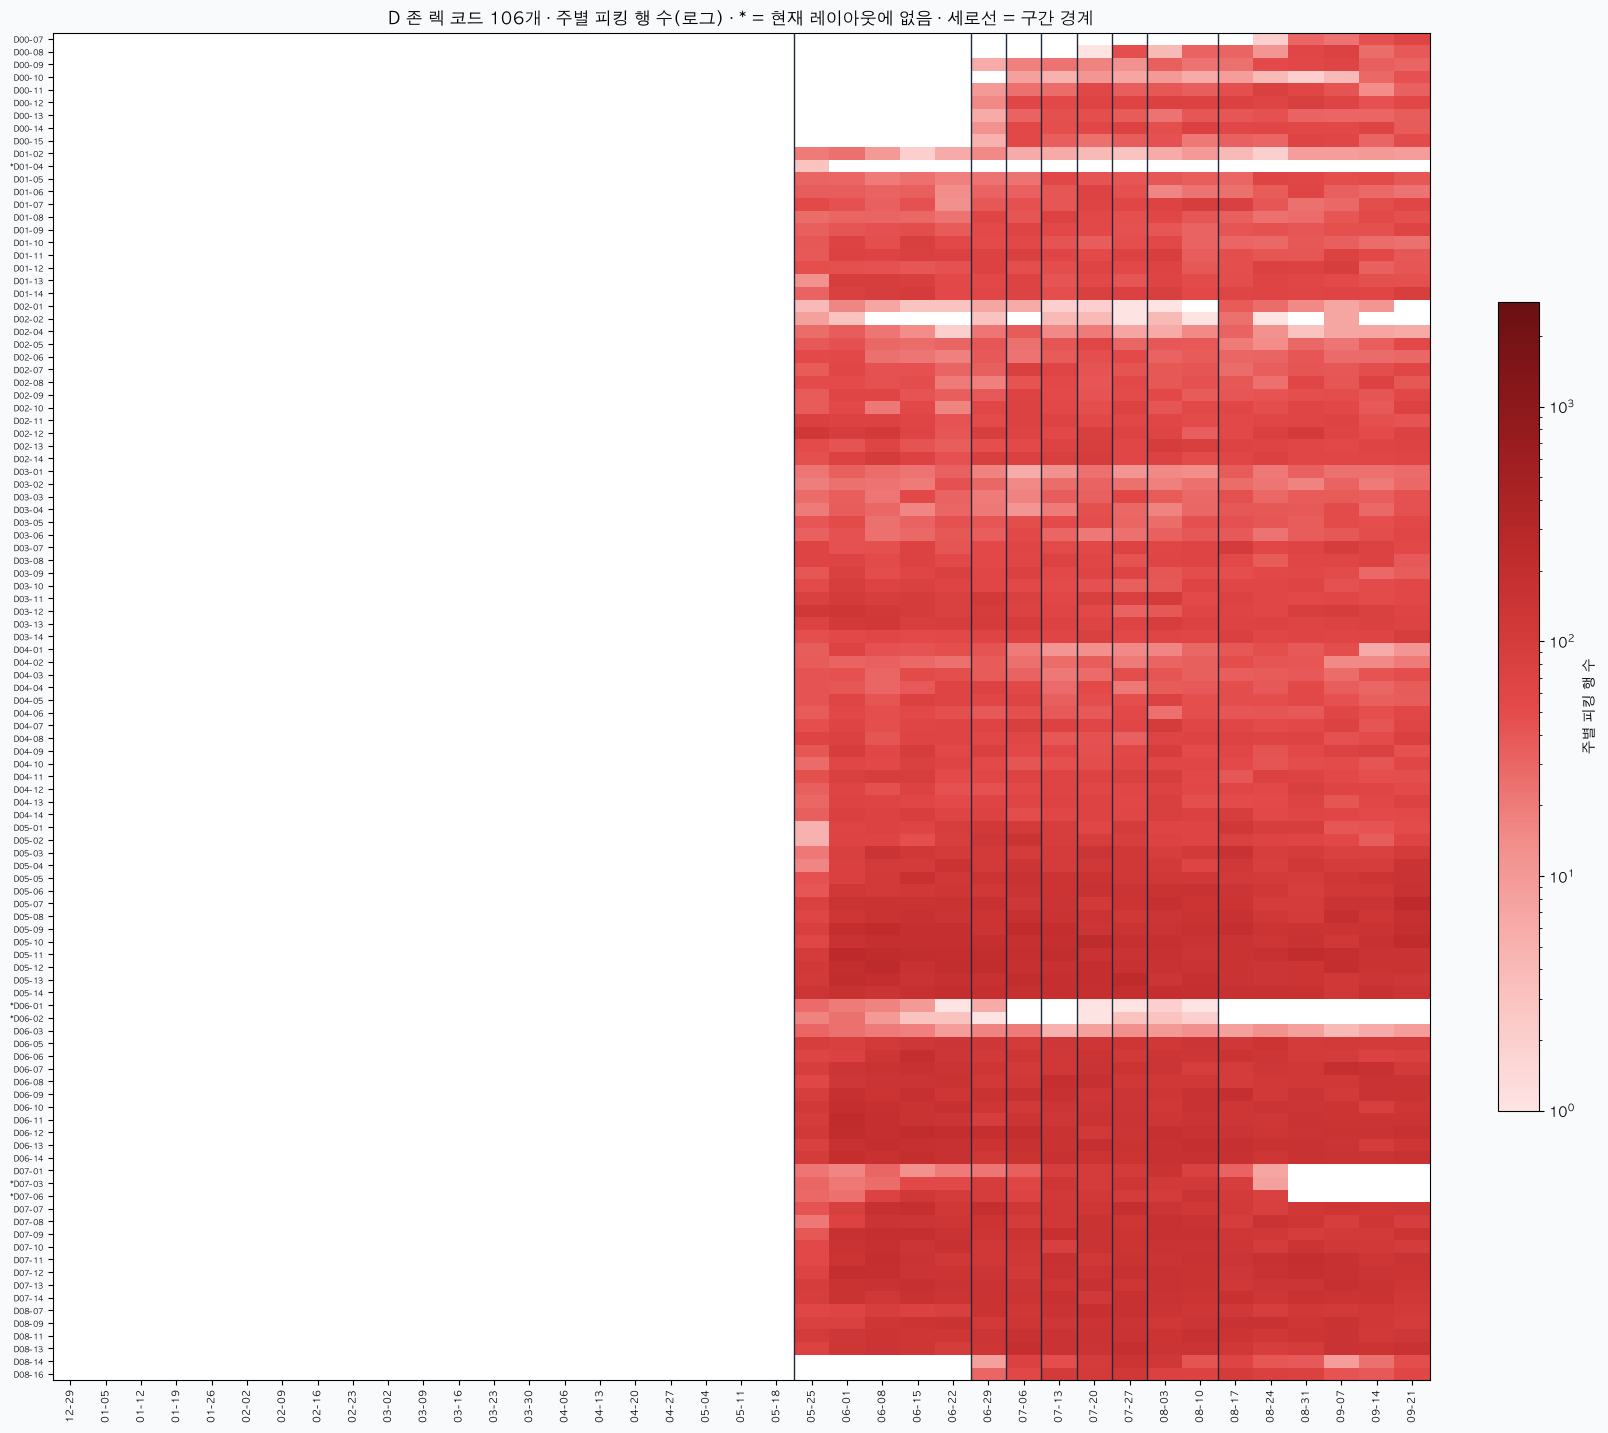

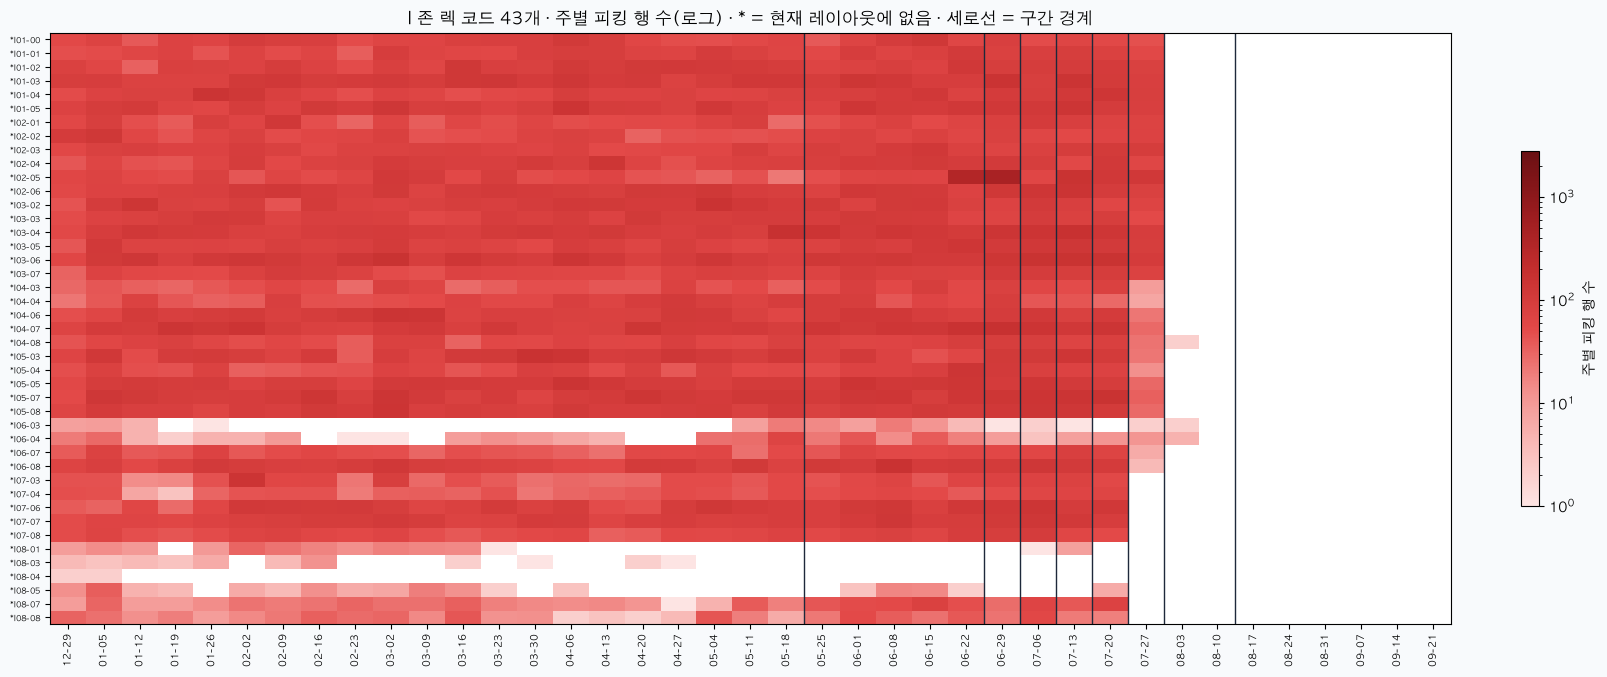

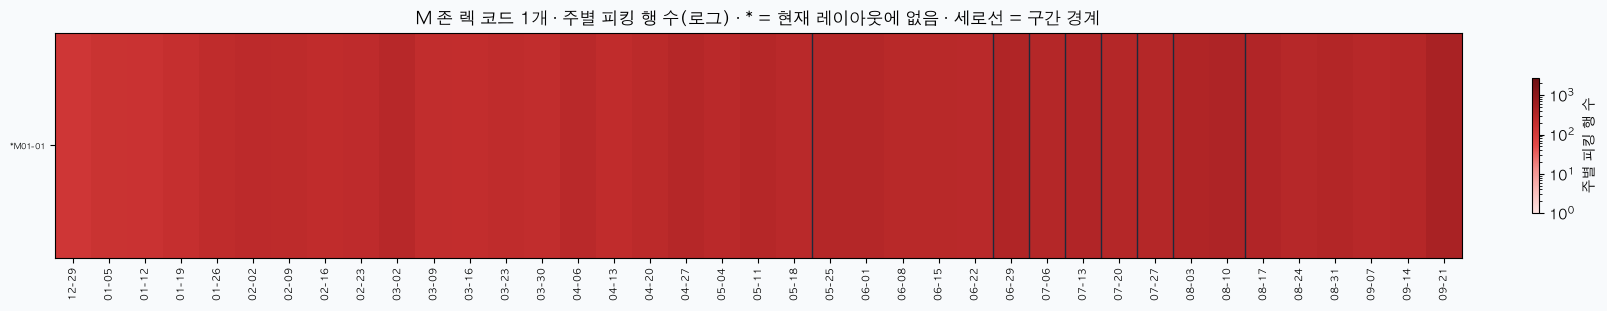

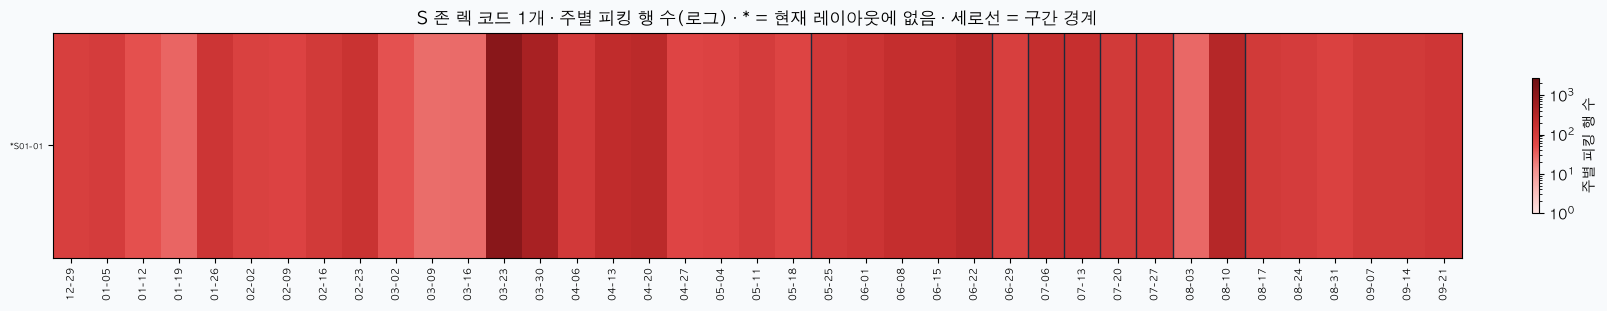

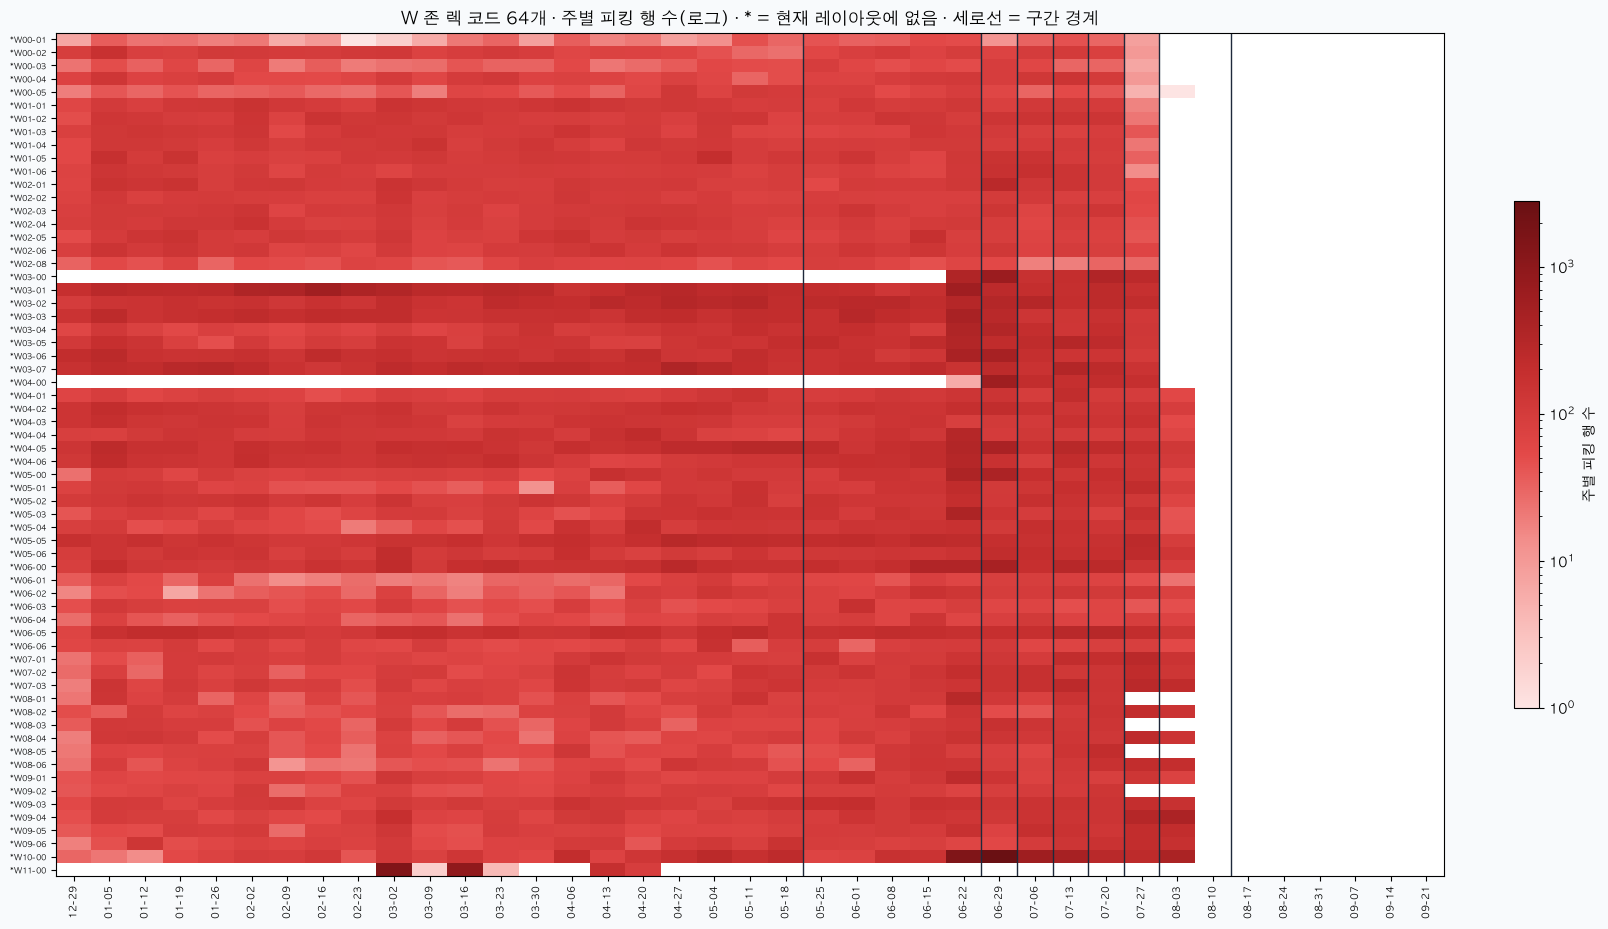

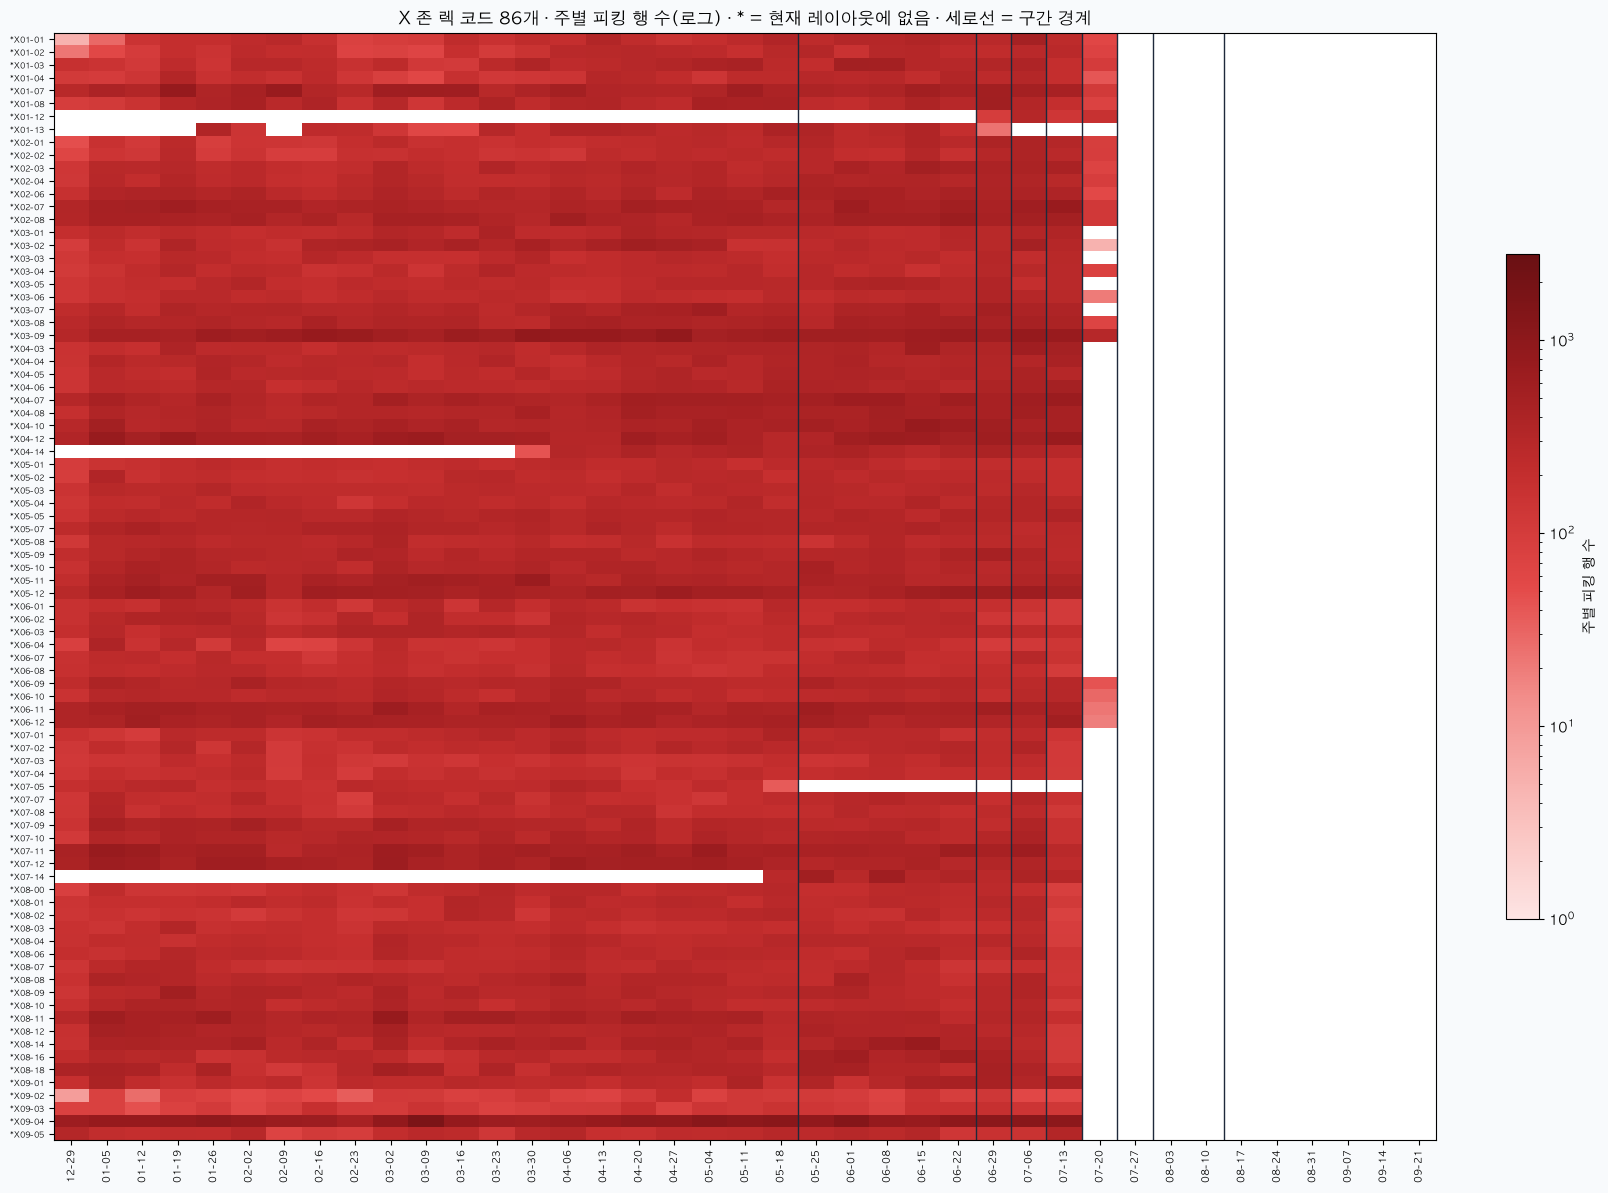

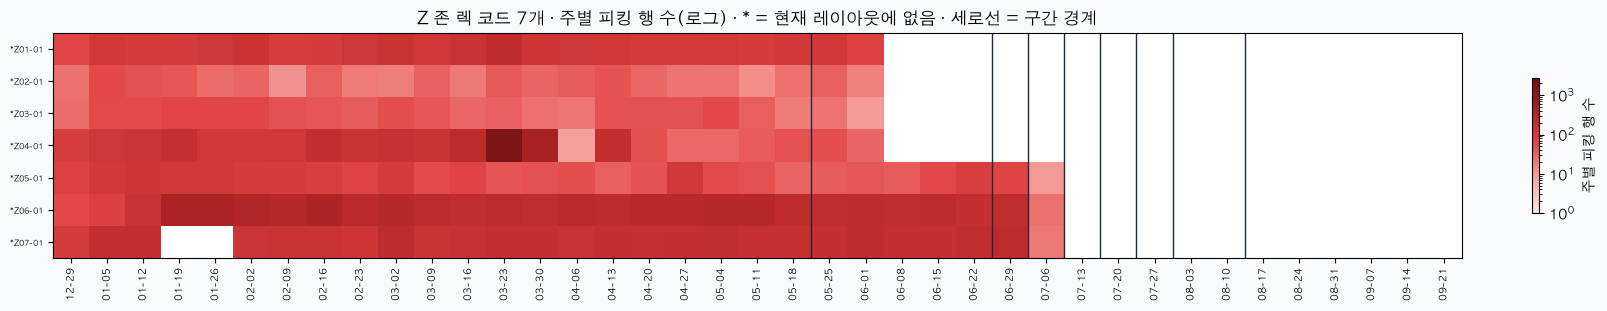

In [6]:
NORM = LogNorm(vmin=1, vmax=weekly.to_numpy().max())
for zone in sorted(daily["zone"].unique()):
    block = weekly.loc[weekly.index.str[0] == zone].sort_index()
    height = max(3, 0.12 * len(block) + 1.5)
    fig, ax = plt.subplots(figsize=(16, height), layout="constrained")
    data = np.ma.masked_equal(block.to_numpy(), 0)
    ax.imshow(data, aspect="auto", cmap=REDS, norm=NORM, interpolation="nearest")
    ax.set_facecolor("#ffffff")
    for start in period_starts[1:]:
        ax.axvline(WEEKS.get_loc(start) - 0.5, color="#1e293b", linewidth=1)
    ax.set_xticks(range(len(WEEKS)))
    ax.set_xticklabels([f"{w:%m-%d}" for w in WEEKS], rotation=90, fontsize=7)
    step = max(1, len(block) // 60)
    ax.set_yticks(range(0, len(block), step))
    ax.set_yticklabels([("" if c in CURRENT else "*") + c for c in block.index[::step]],
                       fontsize=6)
    ax.set_title(f"{zone} 존 렉 코드 {len(block)}개 · 주별 피킹 행 수(로그) · "
                 f"* = 현재 레이아웃에 없음 · 세로선 = 구간 경계", fontsize=12)
    fig.colorbar(plt.cm.ScalarMappable(norm=NORM, cmap=REDS), ax=ax, shrink=0.6,
                 label="주별 피킹 행 수")
    fig.savefig(OUTPUT / f"timeline_{zone}.png", dpi=140, bbox_inches="tight")
    plt.show()

## 6. 현재 존(A·B·C·D) 코드 중 현재 레이아웃과 다른 코드

현재 레이아웃에 없는 A·B·C·D 코드, 그리고 현재 레이아웃에 있지만 중간에 끊기거나 늦게 시작한
코드를 정리합니다. 2026-08-10 이후 구간을 기준으로 봅니다.

In [7]:
recent = life.loc[life["zone"].isin(list("ABCD")) & (life["last_day"] >= "2026-08-10")].copy()
not_in_layout = recent.loc[~recent["in_current_layout"]]
late_start = recent.loc[recent["in_current_layout"] & (recent["first_day"] > "2026-08-16")]
early_end = recent.loc[recent["in_current_layout"] & (recent["last_day"] < LAST_DAY - pd.Timedelta(days=13))]
columns = ["first_day", "last_day", "rows", "active_days", "gaps_3w_plus"]
print("현재 레이아웃에 없는 코드 (8/10 이후 관측)")
display(not_in_layout[columns].sort_values("rows", ascending=False))
print("현재 레이아웃에 있지만 8/17 이후 처음 관측")
display(late_start[columns].sort_values("first_day"))
print("현재 레이아웃에 있지만 마지막 2주 전에 관측이 끝남")
display(early_end[columns].sort_values("last_day"))

현재 레이아웃에 없는 코드 (8/10 이후 관측)


,first_day,last_day,rows,active_days,gaps_3w_plus
rack_code,,,,,
A00-00,2026-01-01,2026-08-17,35226,185,07-06~08-16
D07-06,2026-05-27,2026-08-30,1253,95,
D07-03,2026-05-27,2026-08-29,1012,93,
C03-14,2026-07-04,2026-08-15,98,12,07-20~08-09
D06-01,2026-05-27,2026-08-13,86,31,
D06-02,2026-05-27,2026-08-14,67,30,
B01-05,2026-08-18,2026-08-25,47,7,
A08-22,2026-06-13,2026-08-25,4,4,06-15~07-19


현재 레이아웃에 있지만 8/17 이후 처음 관측


,first_day,last_day,rows,active_days,gaps_3w_plus
rack_code,,,,,
B02-09,2026-08-17,2026-09-27,418,32,
B01-10,2026-08-17,2026-09-26,327,28,
B02-05,2026-08-17,2026-09-22,195,23,
B07-13,2026-08-17,2026-09-26,664,29,
B02-10,2026-08-17,2026-09-24,301,26,
B05-14,2026-08-17,2026-09-27,535,29,
B06-13,2026-08-17,2026-09-16,338,19,
B06-14,2026-08-18,2026-09-27,652,37,
B03-10,2026-08-18,2026-09-27,403,29,


현재 레이아웃에 있지만 마지막 2주 전에 관측이 끝남


,first_day,last_day,rows,active_days,gaps_3w_plus
rack_code,,,,,
D07-01,2026-05-27,2026-08-29,721,87,
C00-16,2026-07-09,2026-09-03,2220,57,
C02-14,2026-07-04,2026-09-03,994,62,
C00-14,2026-07-04,2026-09-08,4803,67,
D02-02,2026-05-29,2026-09-13,60,29,06-08~06-28
